In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import difflib
import scipy
import plotly.express as px
import plotly.io as pio

pio.renderers.default = "png"


In [2]:

raw_files = [f"annual_reports/{year}.csv" for year in range(2015,2020)] 
dblist = [pd.read_csv(file) for file in raw_files]
years = np.arange(2015,2020)

-----

1. What does the distribution of the variable Score loook like? (Histograms?)

Something that quickly becomes apparent is the mismatch of labeling between the datasets. So rather than evoking the database columns directly, I'm using pandas's `db.like` function.

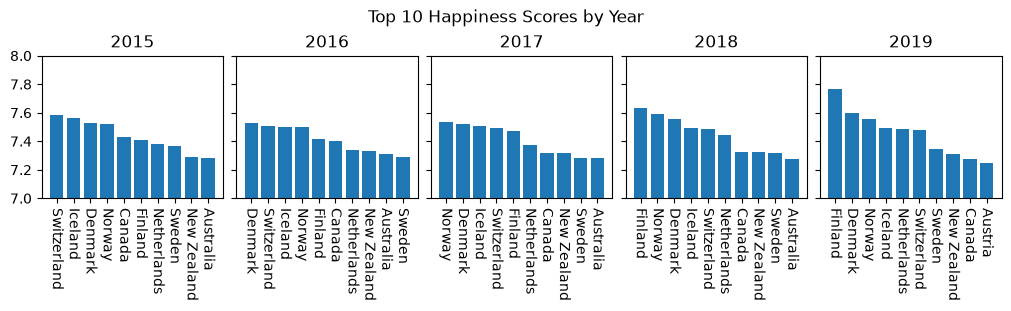

In [3]:

fig1, axes1 = plt.subplots(1,5, figsize = (10,3), constrained_layout = True)
axes1[0].set_ylim(7,8)
axes1[0].set_yticks(np.arange(7,8.2,.2),[f'{a:.1f}' for a in np.arange(7,8.2,.2)])
for year,db, ax in zip(years,dblist,axes1):
    ax.bar(db.filter(regex='(?i)Country').iloc[:, 0][:10],db.filter(regex='(?i)Score').iloc[:, 0][:10])
    ax.tick_params(axis = 'x', rotation = -90)
    ax.set_title(f'{year}')

    if ax != axes1[0]:
        ax.sharey(axes1[0])
        ax.tick_params(labelleft = False)


fig1.suptitle('Top 10 Happiness Scores by Year');


In [4]:
dblist[1]

,Country,Region,Happiness Rank,Happiness Score,Lower Confidence Interval,Upper Confidence Interval,Economy (GDP per Capita),Family,Health (Life Expectancy),Freedom,Trust (Government Corruption),Generosity,Dystopia Residual
0,Denmark,Western Europe,1,7.526,7.460,7.592,1.44178,1.16374,0.79504,0.57941,0.44453,0.36171,2.73939
1,Switzerland,Western Europe,2,7.509,7.428,7.590,1.52733,1.14524,0.86303,0.58557,0.41203,0.28083,2.69463
2,Iceland,Western Europe,3,7.501,7.333,7.669,1.42666,1.18326,0.86733,0.56624,0.14975,0.47678,2.83137
3,Norway,Western Europe,4,7.498,7.421,7.575,1.57744,1.12690,0.79579,0.59609,0.35776,0.37895,2.66465
4,Finland,Western Europe,5,7.413,7.351,7.475,1.40598,1.13464,0.81091,0.57104,0.41004,0.25492,2.82596
...,...,...,...,...,...,...,...,...,...,...,...,...,...
152,Benin,Sub-Saharan Africa,153,3.484,3.404,3.564,0.39499,0.10419,0.21028,0.39747,0.06681,0.20180,2.10812
153,Afghanistan,Southern Asia,154,3.360,3.288,3.432,0.38227,0.11037,0.17344,0.16430,0.07112,0.31268,2.14558
154,Togo,Sub-Saharan Africa,155,3.303,3.192,3.414,0.28123,0.00000,0.24811,0.34678,0.11587,0.17517,2.13540
155,Syria,Middle East and Northern Africa,156,3.069,2.936,3.202,0.74719,0.14866,0.62994,0.06912,0.17233,0.48397,0.81789


----
2. Is there any visible relationship between GDP and Healthy? Scatter plot, and label notable countries.

Yes, it seems almost linear.

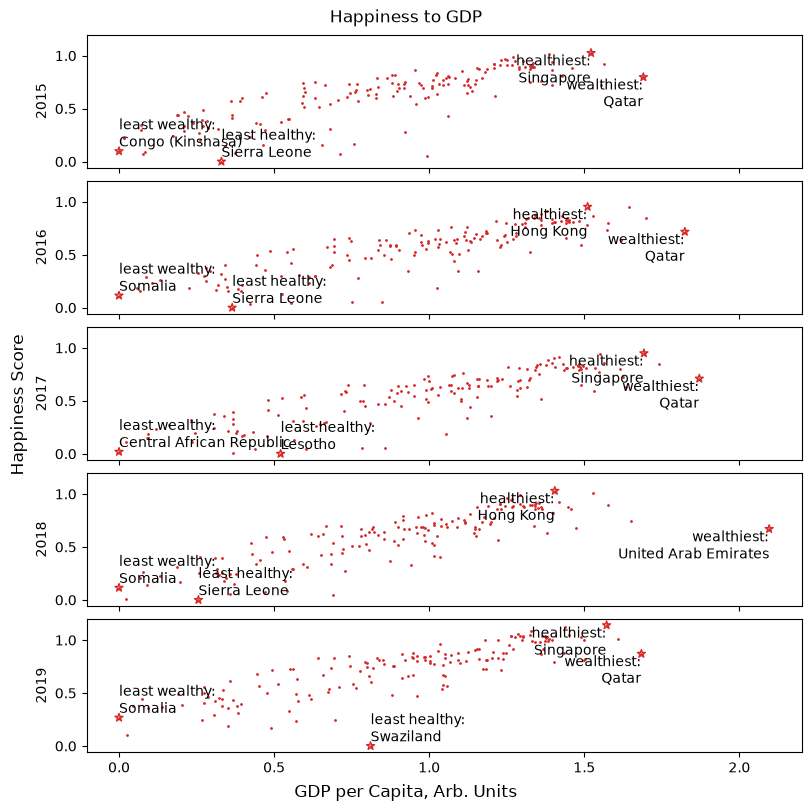

In [5]:
fig2, axes2 = plt.subplots(5,figsize = (8,8), constrained_layout = True)
for i,(db,ax,year) in enumerate(zip(dblist,axes2,years)):
    X = db.filter(like = 'GDP').squeeze()
    Y = db.filter(like = 'Health').squeeze()
    ax.scatter(X,Y, s=1,c='tab:red')

    happiness = db.filter(like = 'Score').squeeze()
    countries = db.filter(like = "Country").squeeze()
    wealthDex = np.argmax(X)
    poorDex = np.argmin(X)
    healthDex = np.argmax(Y)
    sickDex = np.argmin(Y)
    happyDex = np.argmax(happiness)
    sadDex = np.argmin(happiness)

    notableDexes = [
        wealthDex, poorDex, healthDex, sickDex
    ]
    notableCountries = [countries[dex] for dex in notableDexes]
    notableTitles = [
        'wealthiest', 'least wealthy', 'healthiest', 'least healthy']
    notableLabels = [f'{title}:\n{country}' for title, country in zip (notableTitles,notableCountries)]
    
    ax.scatter(X[notableDexes],Y[notableDexes], marker = '*', facecolor = "none", edgecolor = 'tab:red')

    for dex,label in zip(notableDexes,notableLabels):
        x,y = X[dex],Y[dex]
        top = (y > (Y.max()-Y.min())/2)
        right =(x> (X.max()-X.min())/2)

        ax.annotate(label,(x,y), ha = ('right' if right else 'left'), va = ('top' if top else 'bottom'))
    if i<4:
        ax.sharex(axes2[4])
        ax.sharey(axes2[4])
    if i<4:
        ax.tick_params(labelbottom = False)
    ax.set_ylabel(f'{year}')
fig2.suptitle("Happiness to GDP");
fig2.supylabel('Happiness Score');
fig2.supxlabel('GDP per Capita, Arb. Units');


We see strong positive correlation.

----
3. Is there any visible relationship between the variables Freedom and Generosity?

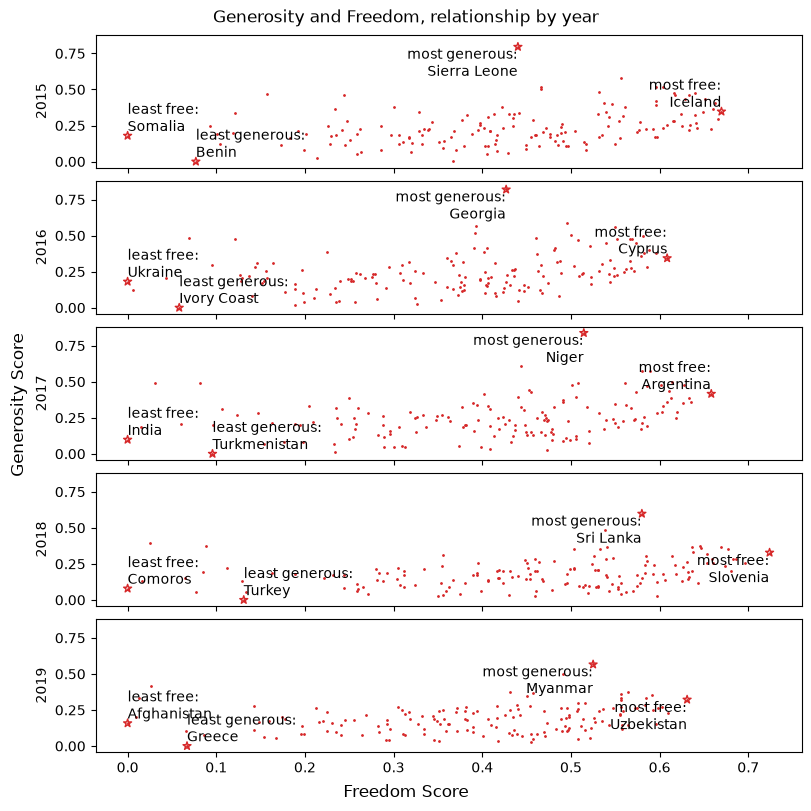

In [6]:
fig3, axes3 = plt.subplots(5,figsize = (8,8), constrained_layout = True)
for i,(db,ax,year) in enumerate(zip(dblist,axes3,years)):
    X = db.filter(like = 'Freedom').squeeze()
    Y = db.filter(like = 'Generosity').squeeze()
    ax.scatter(X,Y, s=1,c='tab:red')


    generosityDex = np.argmax(Y)
    stingyDex = np.argmin(Y)
    freedomDex = np.argmax(X)
    opressionDex = np.argmin(X)

    notableDexes = [
        generosityDex,stingyDex,freedomDex,opressionDex
    ]
    notableCountries = [countries[dex] for dex in notableDexes]
    notableTitles = [
        'most generous', 'least generous', 'most free', 'least free']
    notableLabels = [f'{title}:\n{country}' for title, country in zip (notableTitles,notableCountries)]
    
    ax.scatter(X[notableDexes],Y[notableDexes], marker = '*', facecolor = "none", edgecolor = 'tab:red')

    for dex,label in zip(notableDexes,notableLabels):
        x,y = X[dex],Y[dex]
        top = (y > (Y.max()-Y.min())/2)
        right =(x> (X.max()-X.min())/2)

        ax.annotate(label,(x,y), ha = ('right' if right else 'left'), va = ('top' if top else 'bottom'))


    if i<4:
        ax.sharex(axes3[4])
        ax.sharey(axes3[4])
        ax.tick_params(labelbottom = False)
    ax.set_ylabel(f'{year}')
fig3.suptitle("Generosity and Freedom, relationship by year");
fig3.supylabel('Generosity Score');
fig3.supxlabel('Freedom Score');


We see very small positive correlation. These quantities may have no correlation at all.


-----
4. Is there a relationship between GDP per Capital, Corruption, and Generosity?

Text(0.5, 0.98, 'GDP, Generosity, and Corruption by Year')

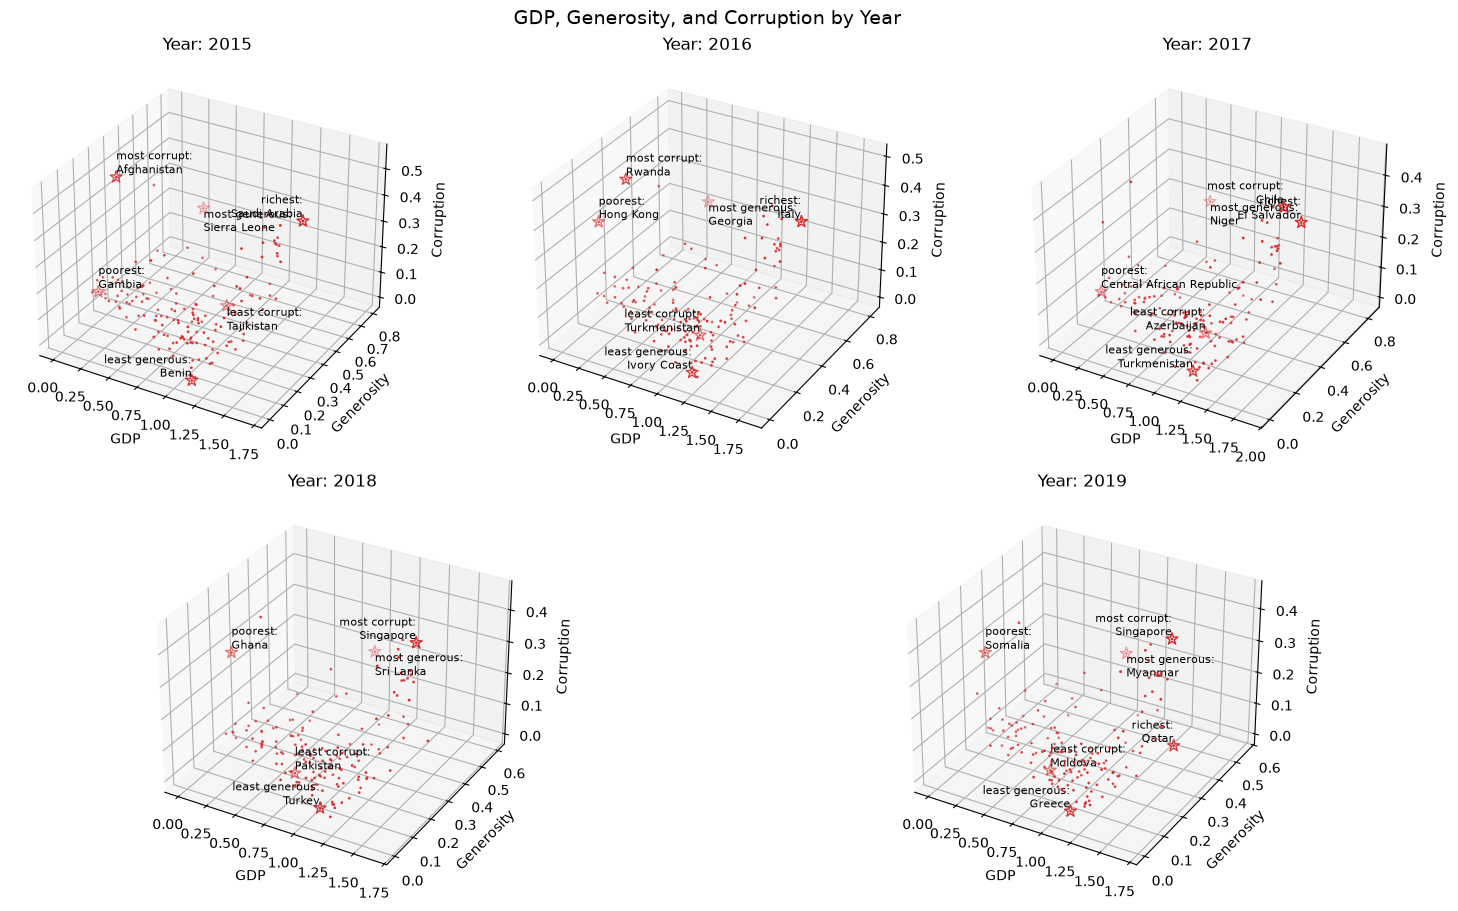

In [7]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Create a wider figure and a 2-row by 6-column GridSpec
fig4 = plt.figure(figsize=(15, 9), constrained_layout=True)
gs = fig4.add_gridspec(2, 6)

# 2. Define the 5 3D subplots (top 3 span 2 cols each; bottom 2 span 3 cols each)
axes4 = [
    fig4.add_subplot(gs[0, 0:2], projection='3d'), # Top-left
    fig4.add_subplot(gs[0, 2:4], projection='3d'), # Top-middle
    fig4.add_subplot(gs[0, 4:6], projection='3d'), # Top-right
    fig4.add_subplot(gs[1, 0:3], projection='3d'), # Bottom-left (centered)
    fig4.add_subplot(gs[1, 3:6], projection='3d')  # Bottom-right (centered)
]

# 3. Your existing loop works without any changes
for i, (db, ax, year) in enumerate(zip(dblist, axes4, years)):
    X = db.filter(regex='(?i)gdp').squeeze()
    Y = db.filter(regex='(?i)generosity').squeeze()
    Z = db.filter(regex='(?i)corruption').squeeze()

    ax.scatter(X, Y, Z, s=1, c='tab:red')

    generosityDex = np.argmax(Y)
    stingyDex = np.argmin(Y)
    richDex = np.argmax(X)
    poorDex = np.argmin(X)
    corruptDex = np.argmax(Z)
    principleDex = np.argmin(Z)

    notableDexes = [
        generosityDex, stingyDex, richDex, poorDex, corruptDex, principleDex
    ]
    notableCountries = [countries[dex] for dex in notableDexes]
    notableTitles = [
        'most generous', 'least generous', 'richest',
        'poorest', 'most corrupt', 'least corrupt'
    ]
    notableLabels = [
        f'{title}:\n{country}' for title, country in zip(notableTitles, notableCountries)
    ]

    ax.scatter(
        X.iloc[notableDexes],
        Y.iloc[notableDexes],
        Z.iloc[notableDexes],
        marker='*',
        facecolor='none',
        edgecolor='tab:red',
        s=80
    )

    for dex, label in zip(notableDexes, notableLabels):
        x, y, z = X.iloc[dex], Y.iloc[dex], Z.iloc[dex]
        top = y > (Y.max() + Y.min()) / 2
        right = x > (X.max() + X.min()) / 2
        
        ax.text(
            x, y, z, label,
            ha=('right' if right else 'left'),
            va=('top' if top else 'bottom'),
            fontsize=8
        )

    ax.set_title(f'Year: {year}')
    ax.set_xlabel('GDP')
    ax.set_ylabel('Generosity')
    ax.set_zlabel('Corruption')

fig4.suptitle("GDP, Generosity, and Corruption by Year", fontsize=14)


The first thing I notice is that there appears to be two distinct populations in the data:

* Group 1 has a strong negative linear correlation between GDP and corruption, with a small, perhaps negligible, positive correlation between generosity and corruption.
* Group 2 has a strong positive linear correlation between generosity and corruption, and little-to-no correlation with GDP, staying tightly in the 0.75 GDP plane.

-----

5. Which countries are missing between consecutive years?

In [8]:


def auto_merge_names(raw_sets):
  # Collect all unique cleaned strings across all years
  all_names = sorted({str(name).strip().title() for s in raw_sets for name in s})

  # Known distinct pairs that look similar to string matchers
  never_merge = {
      frozenset(["Niger", "Nigeria"]),
      frozenset(["Sudan", "South Sudan"]),
      frozenset(["North Korea", "South Korea"]),
      frozenset(["Guinea", "Guinea-Bissau"]),
      frozenset(["Guinea", "Equatorial Guinea"]),
      frozenset(["Guinea", "Papua New Guinea"]),
      frozenset(["Dominica", "Dominican Republic"]),
      frozenset(["Ireland", "Northern Ireland"]),
      frozenset(["Austria", "Australia"]),
      frozenset(["Slovakia", "Slovenia"]),
      frozenset(["Georgia", "South Georgia"]),
      frozenset(["Samoa", "American Samoa"]),
      frozenset(["Virgin Islands", "British Virgin Islands"]),
      frozenset(["Virgin Islands", "U.S. Virgin Islands"]),
  }

  canonical_map = {}
  for name in all_names:
    if name in canonical_map:
      continue
    canonical_map[name] = name

    for other in all_names:
      if other in canonical_map or frozenset([name, other]) in never_merge:
        continue

      # Match if one starts with the other (e.g., "Taiwan" -> "Taiwan Province Of China")
      # or if similarity is very high (e.g., "North Cyprus" <-> "Northern Cyprus")
      is_prefix = other.startswith(name + " ") or other.startswith(name + ",")
      is_similar = difflib.SequenceMatcher(None, name, other).ratio() > 0.85

      if is_prefix or is_similar:
        canonical_map[other] = name

  # Optional: Print merged names so you can verify them
  merges = {k: v for k, v in canonical_map.items() if k != v}
  if merges:
    print("Auto-merged country variants:", merges)

  # Apply the generated mapping to every year's set
  return [
      {canonical_map[str(n).strip().title()] for n in s} for s in raw_sets
  ]


# 1. Extract and auto-normalize country sets per year
raw_countrylistByYear = [
    set(db.filter(regex='(?i)country').iloc[:, 0].dropna()) for db in dblist
]
countrylistByYear = auto_merge_names(raw_countrylistByYear)
countryList = sorted(set().union(*countrylistByYear))

# 2. Build membership ranges
countryMembershipRanges = {country: [] for country in countryList}
final_year_end = int(max(years)) + 1

for country in countryList:
  on = False
  for year, current_year_countries in zip(years, countrylistByYear):
    year_int = int(year)

    if not on and country in current_year_countries:
      countryMembershipRanges[country].append([year_int, None])
      on = True
    elif on and country not in current_year_countries:
      countryMembershipRanges[country][-1][1] = year_int
      on = False

  # Close any range still active in the final year
  if (
      countryMembershipRanges[country]
      and countryMembershipRanges[country][-1][1] is None
  ):
    countryMembershipRanges[country][-1][1] = final_year_end
start_year = int(min(years))
final_year_end = int(max(years)) + 1

# Keep only countries whose ranges are NOT solely [[start_year, final_year_end]]
filteredRanges = {
    country: ranges
    for country, ranges in countryMembershipRanges.items()
    if ranges != [[start_year, final_year_end]]
}

Auto-merged country variants: {'Hong Kong S.A.R., China': 'Hong Kong', 'Ireland': 'Iceland', 'Northern Cyprus': 'North Cyprus', 'Taiwan Province Of China': 'Taiwan', 'Trinidad And Tobago': 'Trinidad & Tobago'}


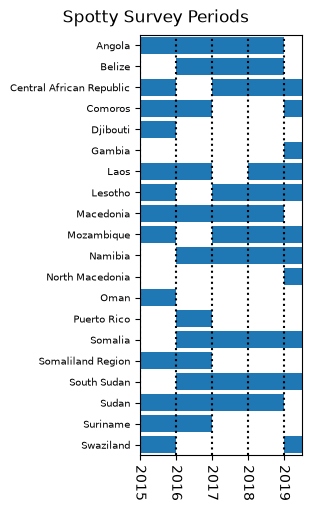

In [9]:
fig5, ax = plt.subplots(figsize = [3,5], constrained_layout = True)
for idx, country in enumerate(filteredRanges):
    xranges = countryMembershipRanges[country]
    xtuples = [(range[0],range[1]-range[0]) for range in xranges]
    ax.broken_barh(xtuples,(idx,.8),'center')

ax.set_yticks(np.arange(len(filteredRanges)),filteredRanges.keys());
ax.set_ylim(0-.5,len(filteredRanges)-.5)
ax.yaxis.set_inverted(True)
ax.set_xticks(years,years, rotation = -90)
ax.set_xlim(2015,2019.5)

ax.tick_params(axis = 'y', labelsize = 'x-small')
fig5.suptitle('Spotty Survey Periods')
for year in years:
    ax.axvline(year, color = 'k', linestyle = 'dotted')

Here you go.

-----
5. Pearson, SPearman, Kenda''s Rank Correlation for the following pairs:
   * Happiness, Generosity
   * Freedom, Generosity
   * GDP per Capita, Corruption
   * GDP per Capita, Corruption 

In [10]:
pairs = [
    ('Score', 'Generosity'),
    ('Freedom', 'Generosity'),
    ('GDP', 'Corruption'),
    ('GDP', 'Freedom')
]

pearson = scipy.stats.pearsonr
spearman = scipy.stats.spearmanr
kendall = scipy.stats.kendalltau
devices = [pearson, spearman, kendall]
devicenames = ['pearson','spearman','kendall']

for year, db in zip(years,dblist):
    print(f'year:{year}')
    for A,B in pairs:
        print(f'\t{A}:{B}')
        X = db.filter(regex=f'(?i){A}').squeeze()
        Y = db.filter(regex=f'(?i){B}').squeeze()
        for device, name in zip(devices,devicenames):
            rank,_ = device(X,Y)
            print(f'\t\t{name}: {rank:0.2f}')





year:2015
	Score:Generosity
		pearson: 0.18
		spearman: 0.17
		kendall: 0.11
	Freedom:Generosity
		pearson: 0.37
		spearman: 0.42
		kendall: 0.28
	GDP:Corruption
		pearson: 0.31
		spearman: 0.23
		kendall: 0.14
	GDP:Freedom
		pearson: 0.37
		spearman: 0.42
		kendall: 0.29
year:2016
	Score:Generosity
		pearson: 0.16
		spearman: 0.15
		kendall: 0.10
	Freedom:Generosity
		pearson: 0.36
		spearman: 0.40
		kendall: 0.27
	GDP:Corruption
		pearson: 0.29
		spearman: 0.22
		kendall: 0.14
	GDP:Freedom
		pearson: 0.36
		spearman: 0.40
		kendall: 0.28
year:2017
	Score:Generosity
		pearson: 0.16
		spearman: 0.14
		kendall: 0.09
	Freedom:Generosity
		pearson: 0.32
		spearman: 0.35
		kendall: 0.23
	GDP:Corruption
		pearson: 0.35
		spearman: 0.25
		kendall: 0.16
	GDP:Freedom
		pearson: 0.37
		spearman: 0.41
		kendall: 0.28
year:2018
	Score:Generosity
		pearson: 0.14
		spearman: 0.11
		kendall: 0.07
	Freedom:Generosity
		pearson: 0.30
		spearman: 0.35
		kendall: 0.24
	GDP:Corruption
		pearson: nan
		sp

-----

7. Identify the variables with the strongest relationship with Happiness Scores.

In [11]:

otherQuantities = [
    'GDP','Family','Health','Freedom','Corruption','Generosity','Dystopia'
]
data = {year:{qty: None for qty in otherQuantities} for year in years}

for year,db in zip(data,dblist):
    for qty in otherQuantities:
        
        X = db.filter(regex='(?i)Score').squeeze()
        Y = db.filter(regex=f'(?i){qty}').squeeze()
        if Y.empty:
            continue
        rank,_ = pearson(X,Y)
        data[year][qty] = rank

correlations = pd.DataFrame(data)


In [12]:
correlations

,2015,2016,2017,2018,2019
GDP,0.780966,0.790322,0.812469,0.802124,0.793883
Family,0.740605,0.739252,0.752737,NaN,NaN
Health,0.724200,0.765384,0.781951,0.775814,0.779883
Freedom,0.568211,0.566827,0.570137,0.544280,0.566742
Corruption,0.395199,0.402032,0.429080,NaN,0.385613
Generosity,0.180319,0.156848,0.155256,0.135825,0.075824
Dystopia,0.530474,0.543738,0.475355,NaN,NaN


According to Pearson Rank, the strongest correlations to happiness are GDP, Health, and Family in descending order.

-----

8. Create a world map color-coding happiness score.

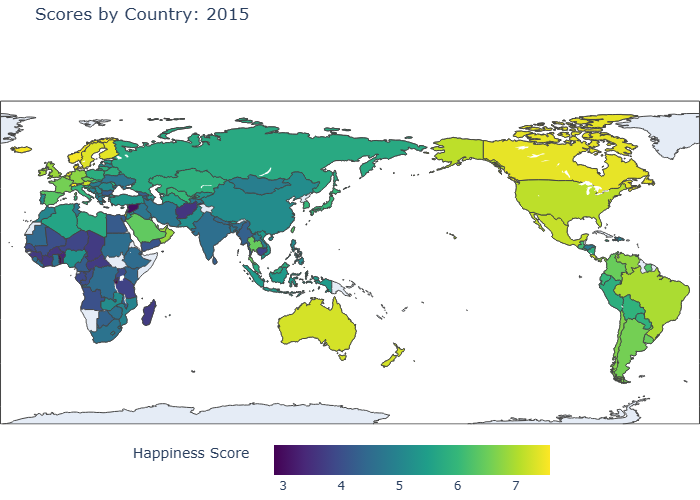

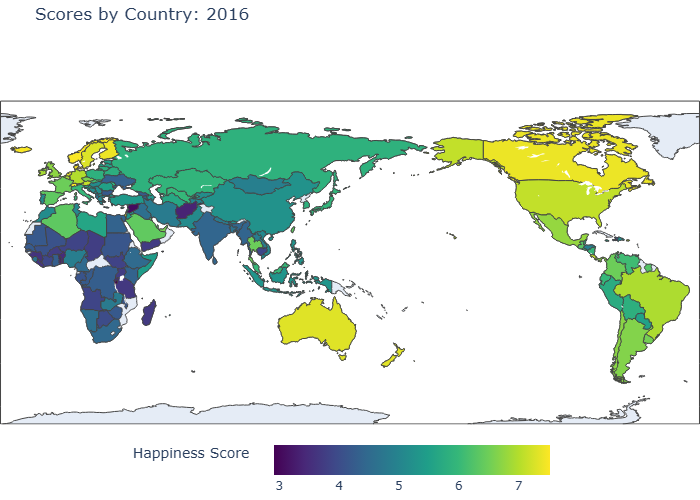

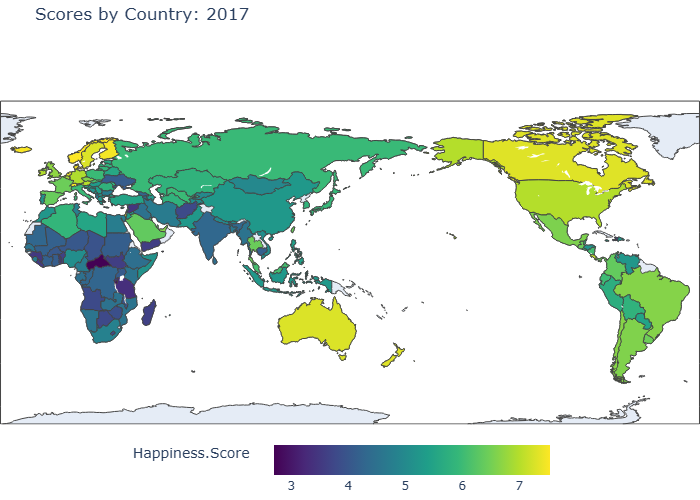

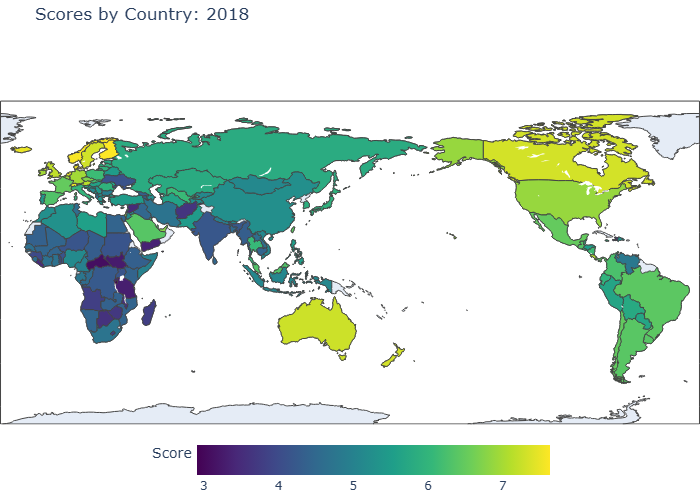

In [ ]:
for year, db in zip(years,dblist):
    score_series = db.filter(regex='(?i)Score').squeeze()
    country_series = db.filter(regex='(?i)Country').squeeze()
    fig = px.choropleth(
        db,
        locations=country_series,
        locationmode="country names",  # Use "ISO-3" if using codes like 'USA', 'CAN'
        color=score_series,
        color_continuous_scale="Viridis",  # Other nice options: "Blues", "Reds", "Plasma"
        title=f"Scores by Country: {year}"
    )
    fig.update_layout(
    # Shrink outer whitespace (l=left, r=right, t=top, b=bottom in pixels)
    margin=dict(l=0, r=0, t=40, b=0),
    
    # Optional: Move the colorbar horizontally below the map so the map spans full width
    coloraxis_colorbar=dict(
        orientation="h",
        yanchor="bottom",
        y=-0.1,
        xanchor="center",
        x=0.5,
        len=0.6  # Width of the colorbar (60% of figure width)
        )
    )
    fig.show('png')

Done.

-----

9. Analyze trends in happiness rank by year and region.

Nah no thanks.